# Ames Housing Price Prediction

## Project Overview

The objective of this project is to build a Machine Learning model that predicts the sale price of residential houses in Ames, Iowa, based on different property characteristics.

The dataset contains information about house size, quality, location, construction year, garage, basement, and other features.

This project explores different regression algorithms, preprocessing techniques, feature engineering, and model evaluation methods to identify a model that can predict house prices accurately.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import os

os.listdir("/content/drive/MyDrive/house_prices ML")

['data_description.txt', 'sample_submission.csv', 'test.csv', 'train.csv']

#1. Load train.csv and test.csv

## Problem Statement

House prices depend on multiple factors, including property size, overall quality, location, age, and available facilities.

The goal is to develop a regression model that learns the relationship between these features and house sale prices, and uses that relationship to predict prices for unseen properties.

In [5]:
train = pd.read_csv(
    "/content/drive/MyDrive/house_prices ML/train.csv"
)

test = pd.read_csv(
    "/content/drive/MyDrive/house_prices ML/test.csv"
)

In [6]:
print("Train shape:", train.shape)              #verify everything
print("Test shape :", test.shape)
train.head()


Train shape: (1460, 81)
Test shape : (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


#2.Understand the dataset

In [8]:
train.columns #Check all columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [9]:
train.info()
#check data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

##check missing values

## Missing Value Analysis

Missing values are examined across the dataset to understand their frequency and distribution.

In the Ames Housing dataset, some missing values represent the absence of a property feature rather than missing information. For example, a missing pool quality value may indicate that the house does not have a pool.

Therefore, missing values are handled according to the meaning of each feature, using suitable imputation strategies.

In [10]:
missing = train.isnull().sum()
missing = missing[missing > 0]
missing.sort_values(ascending=False)


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [11]:
train.isnull().sum().sum()

np.int64(7829)

In [12]:
train["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


In [13]:
train["SalePrice"].isnull().sum()

np.int64(0)

## Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the distribution of house prices and identify relationships between different property features and the target variable.

The analysis includes:
- Examining the distribution of `SalePrice`.
- Studying relationships between numerical features and house prices.
- Understanding categorical feature distributions.
- Identifying correlations between important variables.
- Detecting unusual observations and potential outliers.

These observations help guide preprocessing and feature selection decisions.

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness: 1.8828757597682129


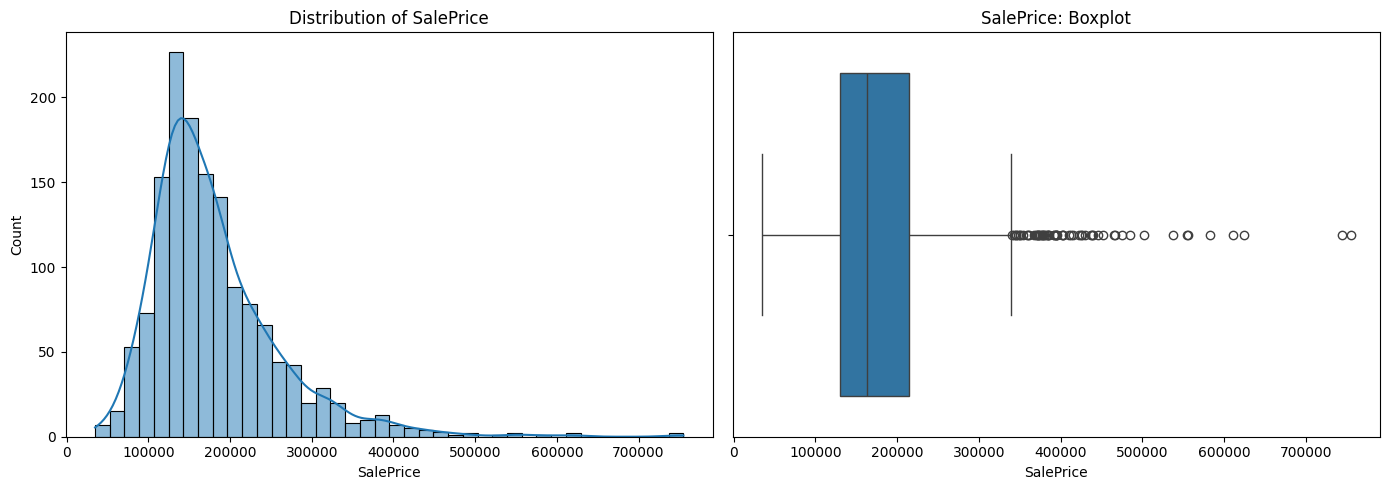

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

# Statistical summary of the target
print(train["SalePrice"].describe())

# Check skewness
print("\nSkewness:", train["SalePrice"].skew())

# Visualize the distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train["SalePrice"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of SalePrice")

sns.boxplot(x=train["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice: Boxplot")

plt.tight_layout()
plt.show()


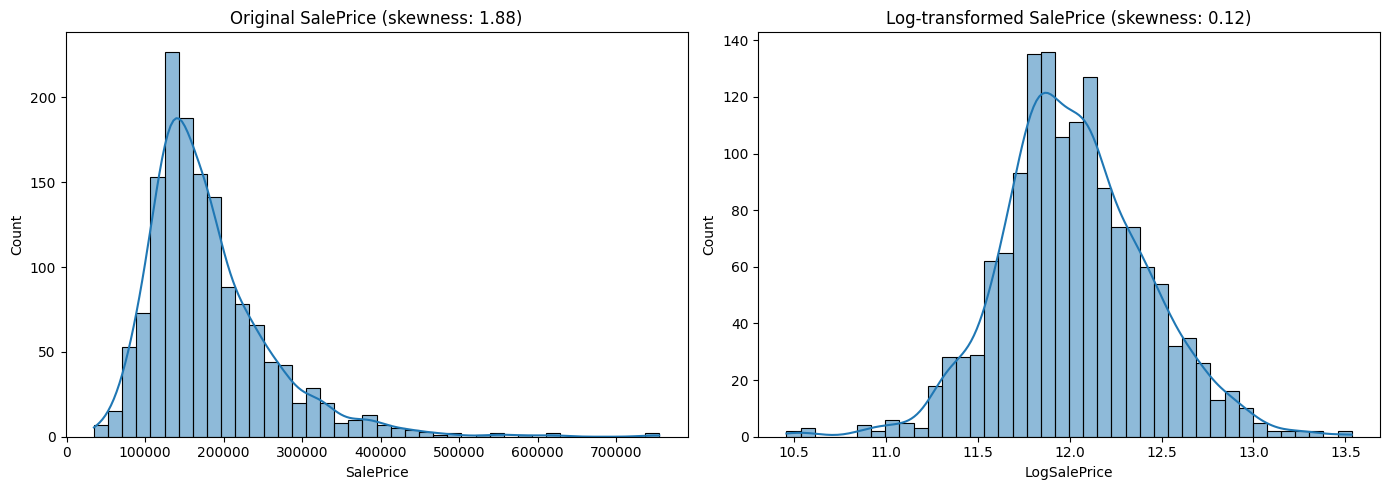

In [15]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train["LogSalePrice"] = np.log1p(train["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train["SalePrice"], bins=40, kde=True, ax=axes[0])
axes[0].set_title(
    f"Original SalePrice (skewness: {train['SalePrice'].skew():.2f})"
)

sns.histplot(train["LogSalePrice"], bins=40, kde=True, ax=axes[1])
axes[1].set_title(
    f"Log-transformed SalePrice (skewness: {train['LogSalePrice'].skew():.2f})"
)

plt.tight_layout()
plt.show()


Top 15 numeric features by absolute correlation:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.351799
dtype: float64


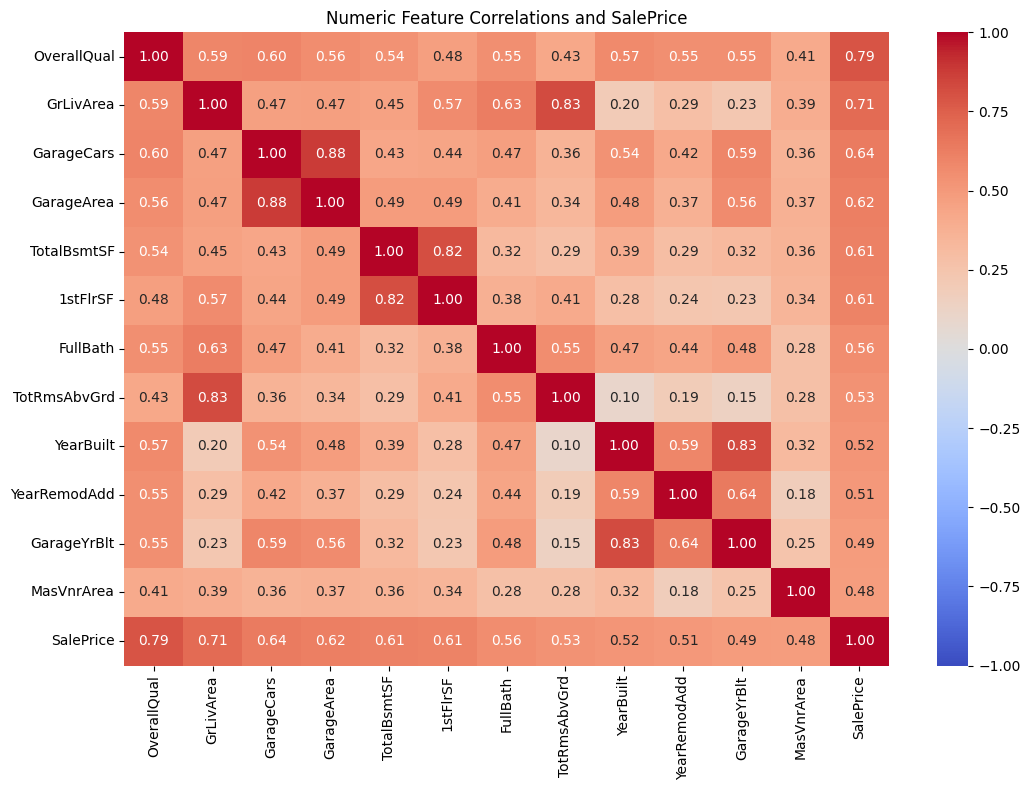

In [16]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude identifiers and all target-derived columns
excluded = ["Id", "SalePrice", "LogSalePrice"]

numeric_features = (
    train.select_dtypes(include=np.number)
    .drop(columns=excluded, errors="ignore")
)

# Correlation of each numeric feature with the original target
target_corr = (
    numeric_features.corrwith(train["SalePrice"])
    .dropna()
    .sort_values(key=abs, ascending=False)
)

print("Top 15 numeric features by absolute correlation:")
print(target_corr.head(15))

# Plot the strongest 12 numeric features, plus SalePrice
selected_features = target_corr.head(12).index.tolist()
plot_data = train[selected_features + ["SalePrice"]]

plt.figure(figsize=(11, 8))
sns.heatmap(
    plot_data.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Numeric Feature Correlations and SalePrice")
plt.tight_layout()
plt.show()


In [17]:

import pandas as pd

# Separate numeric and categorical columns
numeric_cols = train.select_dtypes(include="number").columns
categorical_cols = train.select_dtypes(exclude="number").columns

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

# Missing-value summary
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "MissingCount": missing,
    "MissingPercent": (missing / len(train) * 100).round(2),
    "DataType": train[missing.index].dtypes.astype(str)
})

print("\nColumns with missing values:")
print(missing_summary.to_string())

# Target availability
print("\nMissing target values:", train["SalePrice"].isnull().sum())


Numeric columns: 39
Categorical columns: 43

Columns with missing values:
              MissingCount  MissingPercent DataType
PoolQC                1453           99.52   object
MiscFeature           1406           96.30   object
Alley                 1369           93.77   object
Fence                 1179           80.75   object
MasVnrType             872           59.73   object
FireplaceQu            690           47.26   object
LotFrontage            259           17.74  float64
GarageType              81            5.55   object
GarageYrBlt             81            5.55  float64
GarageFinish            81            5.55   object
GarageQual              81            5.55   object
GarageCond              81            5.55   object
BsmtExposure            38            2.60   object
BsmtFinType2            38            2.60   object
BsmtQual                37            2.53   object
BsmtCond                37            2.53   object
BsmtFinType1            37            2.53

In [18]:

# Inspect representative missing-value patterns

columns_to_check = [
    "PoolQC", "MiscFeature", "Alley", "Fence",
    "FireplaceQu", "LotFrontage",
    "GarageType", "GarageYrBlt", "GarageCars",
    "BsmtQual", "BsmtExposure", "TotalBsmtSF",
    "MasVnrType", "MasVnrArea", "Electrical"
]

for col in columns_to_check:
    if col in train.columns:
        print(f"\n--- {col} ---")
        print("Missing:", train[col].isna().sum())
        print("Observed values:")
        print(train[col].value_counts(dropna=False).head(10))

# Compare garage missingness with garage capacity
print("\nGarageType missing vs GarageCars:")
print(pd.crosstab(
    train["GarageType"].isna(),
    train["GarageCars"],
    margins=True
))

# Compare basement quality missingness with basement area
print("\nBsmtQual missing vs TotalBsmtSF:")
print(train.loc[
    train["BsmtQual"].isna(),
    ["BsmtQual", "TotalBsmtSF", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]
].head(10))



--- PoolQC ---
Missing: 1453
Observed values:
PoolQC
NaN    1453
Gd        3
Ex        2
Fa        2
Name: count, dtype: int64

--- MiscFeature ---
Missing: 1406
Observed values:
MiscFeature
NaN     1406
Shed      49
Gar2       2
Othr       2
TenC       1
Name: count, dtype: int64

--- Alley ---
Missing: 1369
Observed values:
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

--- Fence ---
Missing: 1179
Observed values:
Fence
NaN      1179
MnPrv     157
GdPrv      59
GdWo       54
MnWw       11
Name: count, dtype: int64

--- FireplaceQu ---
Missing: 690
Observed values:
FireplaceQu
NaN    690
Gd     380
TA     313
Fa      33
Ex      24
Po      20
Name: count, dtype: int64

--- LotFrontage ---
Missing: 259
Observed values:
LotFrontage
NaN     259
60.0    143
70.0     70
80.0     69
50.0     57
75.0     53
65.0     44
85.0     40
78.0     25
21.0     23
Name: count, dtype: int64

--- GarageType ---
Missing: 81
Observed values:
GarageType
Attchd     870
Detchd     38

In [19]:

# Check whether missing fireplace quality means no fireplace
print("FireplaceQu missing vs Fireplaces:")
print(pd.crosstab(
    train["FireplaceQu"].isna(),
    train["Fireplaces"],
    margins=True
))

# Check masonry veneer type and area together
print("\nMasVnrType missing vs MasVnrArea:")
print(pd.crosstab(
    train["MasVnrType"].isna(),
    train["MasVnrArea"].isna(),
    margins=True
))

print("\nRows with missing masonry veneer information:")
print(
    train.loc[
        train["MasVnrType"].isna() | train["MasVnrArea"].isna(),
        ["MasVnrType", "MasVnrArea", "SalePrice"]
    ].head(15)
)

# Inspect all-zero basement indicators for missing basement categories
basement_cols = [
    "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2"
]

print("\nMissing basement categories vs zero basement area:")
for col in basement_cols:
    print(
        col,
        pd.crosstab(
            train[col].isna(),
            train["TotalBsmtSF"].eq(0)
        ).to_dict()
    )


FireplaceQu missing vs Fireplaces:
Fireplaces     0    1    2  3   All
FireplaceQu                        
False          0  650  115  5   770
True         690    0    0  0   690
All          690  650  115  5  1460

MasVnrType missing vs MasVnrArea:
MasVnrArea  False  True   All
MasVnrType                   
False         588     0   588
True          864     8   872
All          1452     8  1460

Rows with missing masonry veneer information:
   MasVnrType  MasVnrArea  SalePrice
1         NaN         0.0     181500
3         NaN         0.0     140000
5         NaN         0.0     143000
8         NaN         0.0     129900
9         NaN         0.0     118000
10        NaN         0.0     129500
12        NaN         0.0     144000
15        NaN         0.0     132000
17        NaN         0.0      90000
18        NaN         0.0     159000
19        NaN         0.0     139000
21        NaN         0.0     139400
23        NaN         0.0     129900
24        NaN         0.0     15400

In [20]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Separate target and predictors
y = train["SalePrice"]
X = train.drop(
    columns=["SalePrice", "LogSalePrice", "Id"],
    errors="ignore"
)

# Identify numeric and categorical predictors
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Categories where missing means the feature is absent
absence_features = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType"
]

absence_features = [
    col for col in absence_features if col in categorical_features
]

other_categorical_features = [
    col for col in categorical_features if col not in absence_features
]

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
absence_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="None"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

other_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing by column group
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("absence", absence_pipeline, absence_features),
    ("categorical", other_categorical_pipeline, other_categorical_features)
])

print("Numeric predictors:", len(numeric_features))
print("Absence-category predictors:", len(absence_features))
print("Other categorical predictors:", len(other_categorical_features))
print("Total predictors:", X.shape[1])



Numeric predictors: 36
Absence-category predictors: 15
Other categorical predictors: 28
Total predictors: 79


In [21]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Separate target and predictors
y = train["SalePrice"]
X = train.drop(
    columns=["SalePrice", "LogSalePrice", "Id"],
    errors="ignore"
)

# Identify numeric and categorical predictors
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Categories where missing means the feature is absent
absence_features = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType"
]

absence_features = [
    col for col in absence_features if col in categorical_features
]

other_categorical_features = [
    col for col in categorical_features if col not in absence_features
]

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
absence_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="None"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

other_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing by column group
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("absence", absence_pipeline, absence_features),
    ("categorical", other_categorical_pipeline, other_categorical_features)
])

print("Numeric predictors:", len(numeric_features))
print("Absence-category predictors:", len(absence_features))
print("Other categorical predictors:", len(other_categorical_features))
print("Total predictors:", X.shape[1])


Numeric predictors: 36
Absence-category predictors: 15
Other categorical predictors: 28
Total predictors: 79


In [22]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Split before fitting any preprocessing
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Combine preprocessing and model into one pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train
baseline_model.fit(X_train, y_train)

# Predict on unseen validation rows
val_predictions = baseline_model.predict(X_val)

# Evaluate in original SalePrice units
mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
r2 = r2_score(y_val, val_predictions)

print(f"Validation MAE:  ${mae:,.2f}")
print(f"Validation RMSE: ${rmse:,.2f}")
print(f"Validation R²:   {r2:.4f}")


Validation MAE:  $20,472.74
Validation RMSE: $31,045.85
Validation R²:   0.8743


## Potential Mistakes and Limitations of the Baseline Linear Regression Model

Our baseline Linear Regression model achieved the following validation results:

- **MAE:** 20,472.74
- **RMSE:** 31,045.85
- **R²:** 0.8743

These results indicate that the model explains approximately 87.43% of the variation in validation-set house prices. However, a good overall score does not guarantee that every prediction is accurate. We need to investigate the following potential limitations.

### 1. Linear Relationship Assumption

Linear Regression models the target as a linear combination of the input features:

\[
\hat{y}=\beta_0+\beta_1x_1+\beta_2x_2+\cdots+\beta_nx_n
\]

Real estate prices may have nonlinear relationships with features such as living area, house quality, and age. For example, the price effect of additional living space may depend on the property's quality or neighborhood.

**Potential impact:** The model may fail to capture complex relationships between features and sale prices.

**Investigation:** Examine residual plots and compare Linear Regression with models capable of learning nonlinear relationships.

### 2. Large Prediction Errors

Our RMSE (31,045.85) is substantially higher than our MAE (20,472.74). Since RMSE penalizes large errors more heavily, this difference suggests that some relatively large prediction errors may be affecting model performance.

**Potential impact:** The model may predict some houses much less accurately than others.

**Investigation:** Calculate error percentiles and inspect the validation examples with the largest absolute errors.

### 3. Multicollinearity Between Features

Some input features are strongly correlated. For example:

- `GarageCars` and `GarageArea`
- `GrLivArea` and `TotRmsAbvGrd`
- `TotalBsmtSF` and `1stFlrSF`
- `YearBuilt` and `GarageYrBlt`

These features may contain overlapping information.

**Potential impact:** Multicollinearity can make individual Linear Regression

Absolute error percentiles:
0.50    14674.32
0.75    25157.56
0.90    40348.05
0.95    53561.81
Name: AbsoluteError, dtype: float64

Mean signed error: 1479.31

10 largest prediction errors:
      Actual  Predicted      Error  AbsoluteError
691   755000  543672.23  211327.77      211327.77
898   611657  432561.27  179095.73      179095.73
1046  556581  412038.84  144542.16      144542.16
774   395000  289364.25  105635.75      105635.75
588   143000  246755.37 -103755.37      103755.37
581   253293  341486.75  -88193.75       88193.75
628   135000  221711.86  -86711.86       86711.86
812    55993  124238.91  -68245.91       68245.91
30     40000  107263.24  -67263.24       67263.24
1243  465000  399701.81   65298.19       65298.19


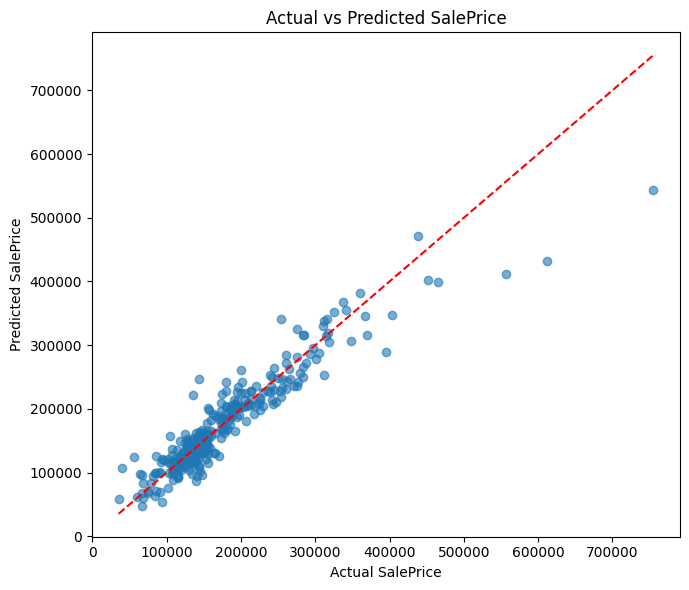

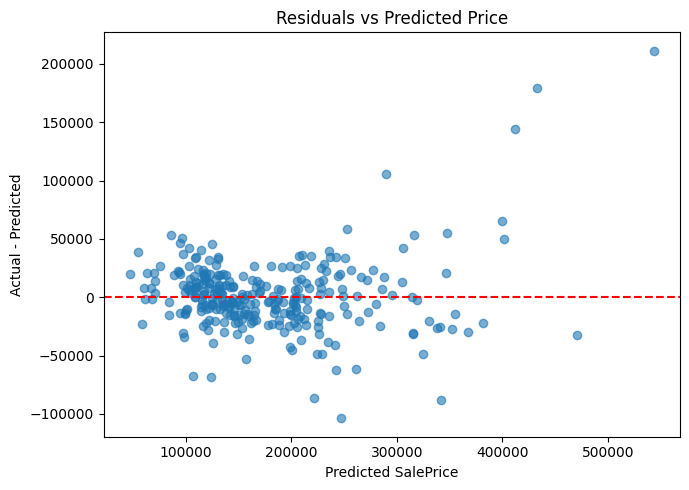

In [23]:
#now let's investigat the mistake


import pandas as pd
import matplotlib.pyplot as plt

# Build a table of actual predictions and their errors
results = pd.DataFrame({
    "Actual": y_val,
    "Predicted": val_predictions
}, index=y_val.index)

results["Error"] = results["Actual"] - results["Predicted"]
results["AbsoluteError"] = results["Error"].abs()

# 1. Understand the distribution of prediction errors
print("Absolute error percentiles:")
print(
    results["AbsoluteError"]
    .quantile([0.50, 0.75, 0.90, 0.95])
    .round(2)
)

print("\nMean signed error:", round(results["Error"].mean(), 2))

# 2. Inspect the 10 largest mistakes
print("\n10 largest prediction errors:")
print(
    results.sort_values("AbsoluteError", ascending=False)
    .head(10)
    .round(2)
)

# 3. Compare actual prices with predicted prices
plt.figure(figsize=(7, 6))
plt.scatter(results["Actual"], results["Predicted"], alpha=0.6)

lower = min(results["Actual"].min(), results["Predicted"].min())
upper = max(results["Actual"].max(), results["Predicted"].max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted SalePrice")
plt.tight_layout()
plt.show()

# 4. Check whether errors have a visible pattern
plt.figure(figsize=(7, 5))
plt.scatter(results["Predicted"], results["Error"], alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted SalePrice")
plt.ylabel("Actual - Predicted")
plt.title("Residuals vs Predicted Price")
plt.tight_layout()
plt.show()


In [24]:

# Group validation predictions by actual sale-price range
results["PriceRange"] = pd.cut(
    results["Actual"],
    bins=[0, 100000, 200000, 300000, 400000, float("inf")],
    labels=[
        "Under 100k",
        "100k–200k",
        "200k–300k",
        "300k–400k",
        "Over 400k"
    ]
)

price_error_analysis = results.groupby(
    "PriceRange", observed=False
).agg(
    Houses=("Actual", "size"),
    MeanActual=("Actual", "mean"),
    MeanPredicted=("Predicted", "mean"),
    MeanError=("Error", "mean"),
    MAE=("AbsoluteError", "mean")
).round(2)

print(price_error_analysis)


            Houses  MeanActual  MeanPredicted  MeanError        MAE
PriceRange                                                         
Under 100k      26    76091.35       87043.57  -10952.23   21449.96
100k–200k      184   145749.93      147443.38   -1693.45   16392.95
200k–300k       58   243004.60      239764.55    3240.05   20081.30
300k–400k       17   332272.18      322450.84    9821.33   29523.28
Over 400k        7   525995.43      429791.71   96203.71  105346.81


## Conclusion: Baseline Linear Regression — Errors and Limitations

Our baseline Linear Regression model achieved a validation MAE of **20,472.74**, RMSE of **31,045.85**, and R² of **0.8743**. These results indicate that the model explains approximately 87.43% of the variation in validation sale prices, making it a promising starting point. However, further investigation revealed several limitations.

### 1. Prediction Errors and Expensive Houses

The actual-versus-predicted plot shows that most predictions cluster reasonably close to the ideal prediction line, but some houses have substantial errors. The largest error occurred for a house with an actual sale price of 755,000, for which the model predicted 543,672.23, resulting in an underprediction of 211,327.77. Other expensive houses were also significantly underpredicted, while some inexpensive houses were overpredicted.

### 2. Error Distribution

The median absolute error was 14,674.32, while the 90th and 95th percentile absolute errors were 40,348.05 and 53,561.81, respectively. The RMSE was considerably higher than the MAE, suggesting that large prediction errors have a noticeable effect on the overall evaluation. The mean signed error was 1,479.31, indicating slight average underprediction overall, although positive and negative errors can cancel each other out.

### 3. Performance Across Price Ranges

Grouping the validation predictions by actual sale price revealed that performance varies considerably across price ranges:

- **Under 100,000:** Mean error of −10,952.23, indicating average overprediction.
- **100,000–200,000:** Mean error of −1,693.45, indicating slight average overprediction.
- **200,000–300,000:** Mean error of 3,240.05, indicating average underprediction.
- **300,000–400,000:** Mean error of 9,821.33, indicating greater average underprediction.
- **Over 400,000:** Mean error of 96,203.71, indicating substantial average underprediction.

The most expensive group contained only seven houses and had an MAE of 105,346.81. Therefore, this result suggests a weakness at the expensive end of the validation set, but the small sample size means the finding should be interpreted cautiously.

### 4. Potential Modeling Limitations

**Linearity:** Linear Regression assumes that predictions can be represented as a linear combination of the input features. It may not fully capture nonlinear relationships between house characteristics and sale prices.

**Multicollinearity:** Some features, such as `GarageCars` and `GarageArea`, are strongly correlated. This can make individual regression coefficients unstable or difficult to interpret, although it does not automatically make predictions inaccurate.

**Target skewness:** The original `SalePrice` distribution has positive skewness of approximately 1.88. This suggests that expensive properties create a long right tail in the target distribution and motivates testing a logarithmic transformation.

**Feature interactions:** The model does not automatically capture every interaction between features. For example, the effect of living area may depend on overall quality or neighborhood.

**Validation uncertainty:** The reported metrics come from a single 80/20 random split. Results may vary with a different split, and validation performance does not guarantee identical performance on the separate Kaggle test dataset.

### 5. Next Experiment: Log-Transforming the Target

The skewness of `log1p(SalePrice)` was approximately 0.12 in our earlier analysis, compared with 1.88 for the original target. We will therefore test Linear Regression using the logarithmically transformed target:

`log1p(SalePrice)`

After prediction, we will apply `expm1()` to return predictions to the original price scale and evaluate them using MAE, RMSE, and R². We will compare these results with the original baseline to determine whether the transformation improves predictive performance.

### Final Conclusion

The baseline Linear Regression model performs reasonably well overall but exhibits substantial errors for some properties, particularly expensive houses. Target skewness, nonlinear relationships, correlated features, and limited representation of expensive properties are potential explanations that require further investigation. The next experiment will test whether transforming the target improves prediction quality rather than assuming that it will.

In [25]:

import numpy as np
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Transform the training target
y_train_log = np.log1p(y_train)

# Build and train a separate model
log_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

log_model.fit(X_train, y_train_log)

# Predict log prices, then convert back to the original scale
val_predictions_log = log_model.predict(X_val)
val_predictions_back = np.expm1(val_predictions_log)

# Evaluate predictions in original SalePrice units
log_mae = mean_absolute_error(y_val, val_predictions_back)
log_rmse = np.sqrt(mean_squared_error(y_val, val_predictions_back))
log_r2 = r2_score(y_val, val_predictions_back)

print("Log-target Linear Regression")
print(f"Validation MAE:  {log_mae:,.2f}")
print(f"Validation RMSE: {log_rmse:,.2f}")
print(f"Validation R²:   {log_r2:.4f}")


Log-target Linear Regression
Validation MAE:  16,969.82
Validation RMSE: 25,451.67
Validation R²:   0.9155


In [26]:

# Compare the two models on the same validation examples
comparison = pd.DataFrame({
    "Actual": y_val,
    "OriginalPrediction": val_predictions,
    "LogPrediction": val_predictions_back
})

comparison["OriginalAbsError"] = (
    comparison["Actual"] - comparison["OriginalPrediction"]
).abs()

comparison["LogAbsError"] = (
    comparison["Actual"] - comparison["LogPrediction"]
).abs()

comparison["PriceRange"] = pd.cut(
    comparison["Actual"],
    bins=[0, 100000, 200000, 300000, 400000, float("inf")],
    labels=[
        "Under 100k",
        "100k–200k",
        "200k–300k",
        "300k–400k",
        "Over 400k"
    ]
)

comparison_by_range = comparison.groupby(
    "PriceRange", observed=False
).agg(
    Houses=("Actual", "size"),
    Original_MAE=("OriginalAbsError", "mean"),
    Log_MAE=("LogAbsError", "mean")
).round(2)

comparison_by_range["MAE_Change"] = (
    comparison_by_range["Original_MAE"]
    - comparison_by_range["Log_MAE"]
).round(2)

print(comparison_by_range)


            Houses  Original_MAE   Log_MAE  MAE_Change
PriceRange                                            
Under 100k      26      21449.96  17667.61     3782.35
100k–200k      184      16392.95  12306.75     4086.20
200k–300k       58      20081.30  20340.69     -259.39
300k–400k       17      29523.28  30462.21     -938.93
Over 400k        7     105346.81  76252.89    29093.92


In [27]:

from sklearn.metrics import mean_absolute_percentage_error
import numpy as np

# Percentage error on the original price scale
mape = mean_absolute_percentage_error(
    y_val, val_predictions_back
) * 100

# An intuitive complement of MAPE
percentage_score = 100 - mape

print(f"MAPE: {mape:.2f}%")
print(f"100 - MAPE: {percentage_score:.2f}%")


MAPE: 10.32%
100 - MAPE: 89.68%


##Ridge Regression
Ridge Regression is a regularized version of Linear Regression. It learns coefficients for our features, but adds a penalty for large coefficients to help prevent the model from relying too heavily on individual features.


Its objective is:
\[
\text{Loss}=\sum_{i=1}^{n}(y_i-\hat y_i)^2
+\alpha\sum_{j=1}^{p}\beta_j^2
\]\

- The first term measures prediction errors.
- The second term penalizes large coefficients.
- \(\alpha\) controls the strength of the penalty. A larger value means stronger regularization.
## Why are we trying it?
- In our dataset, some features are strongly correlated, such as GarageCars and GarageArea. This overlap can make ordinary Linear Regression coefficients unstable.

- Ridge Regression can shrink those coefficients, often making the model more stable. It doesn't automatically eliminate features, and it won't necessarily improve validation performance.

- We'll train Ridge on log-transformed sale prices, because that version of Linear Regression performed better in our previous experiment.

- Next, we'll test several values of \(\alpha\) using cross-validation on the training split, then evaluate the selected model on the same validation set. That gives us a fair comparison with our current best model.

In [28]:
# ridge regression

import numpy as np
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Build the pipeline
ridge_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", Ridge())
])

# Test different regularization strengths
param_grid = {
    "model__alpha": [0.1, 1, 10, 100]
}

# Choose alpha using cross-validation on the training data
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

# Train on log-transformed prices
ridge_search.fit(X_train, np.log1p(y_train))

# Predict prices on the validation set
best_ridge = ridge_search.best_estimator_
ridge_predictions_log = best_ridge.predict(X_val)
ridge_predictions = np.expm1(ridge_predictions_log)

# Evaluate on the original price scale
ridge_mae = mean_absolute_error(y_val, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_val, ridge_predictions))
ridge_r2 = r2_score(y_val, ridge_predictions)

print("Best alpha:", ridge_search.best_params_["model__alpha"])
print(f"Validation MAE:  ₹{ridge_mae:,.2f}")
print(f"Validation RMSE: ₹{ridge_rmse:,.2f}")
print(f"Validation R²:   {ridge_r2:.4f}")


Best alpha: 100
Validation MAE:  ₹17,822.58
Validation RMSE: ₹29,421.19
Validation R²:   0.8871


Ridge Regression performed worse than our Log-Target Linear Regression. Let's understand why before moving on.

#Random Forest model

- Random Forest builds many decision trees and combines their predictions. Unlike Linear Regression, it can learn nonlinear patterns and interactions between features—for example, how the effect of living area might vary with overall house quality.

In [29]:

import numpy as np

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Build the pipeline
rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

# Train on log-transformed sale prices
rf_model.fit(X_train, np.log1p(y_train))

# Predict and convert back to original prices
rf_predictions_log = rf_model.predict(X_val)
rf_predictions = np.expm1(rf_predictions_log)

# Evaluate predictions in rupees
rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))
rf_r2 = r2_score(y_val, rf_predictions)

print(f"Validation MAE:  ₹{rf_mae:,.2f}")
print(f"Validation RMSE: ₹{rf_rmse:,.2f}")
print(f"Validation R²:   {rf_r2:.4f}")


Validation MAE:  ₹17,504.93
Validation RMSE: ₹30,015.38
Validation R²:   0.8825


#tune random forest
- Rather than abandoning it, let's test whether controlling tree complexity improves validation performance. We'll compare different tree depths, minimum leaf sizes, and feature-sampling settings using cross-validation on the training set.

In [30]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

param_distributions = {
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, np.log1p(y_train))

best_rf = rf_search.best_estimator_
predictions = np.expm1(best_rf.predict(X_val))

print("Best parameters:", rf_search.best_params_)
print(f"Validation MAE:  ₹{mean_absolute_error(y_val, predictions):,.2f}")
print(f"Validation RMSE: ₹{np.sqrt(mean_squared_error(y_val, predictions)):,.2f}")
print(f"Validation R²:   {r2_score(y_val, predictions):.4f}")


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': 10}
Validation MAE:  ₹16,992.97
Validation RMSE: ₹28,980.76
Validation R²:   0.8905


In [31]:

import pandas as pd

# Get the fitted Random Forest from our pipeline
rf = best_rf.named_steps["model"]

# Get the feature names after preprocessing
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()

# Match each feature with its importance score
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).reset_index(drop=True)

print(importance_df.head(20).to_string(index=False))


                  Feature  Importance
     numeric__OverallQual    0.414570
       numeric__GrLivArea    0.155598
       numeric__YearBuilt    0.059662
      numeric__GarageCars    0.042322
     numeric__TotalBsmtSF    0.037776
      numeric__GarageArea    0.030491
        numeric__1stFlrSF    0.022693
      numeric__BsmtFinSF1    0.020917
categorical__ExterQual_TA    0.019401
         numeric__LotArea    0.018060
categorical__CentralAir_Y    0.011597
        numeric__2ndFlrSF    0.009679
      numeric__Fireplaces    0.009632
     numeric__OverallCond    0.009520
categorical__CentralAir_N    0.008461
    numeric__YearRemodAdd    0.008023
     numeric__GarageYrBlt    0.007402
     absence__BsmtQual_Ex    0.006605
     numeric__LotFrontage    0.006092
absence__FireplaceQu_None    0.005656


In [32]:

import numpy as np
import pandas as pd

# Use predictions from our best Log-Target Linear Regression model
error_df = pd.DataFrame({
    "ActualPrice": y_val,
    "PredictedPrice": val_predictions_back
})

# Positive error means underprediction; negative means overprediction
error_df["Error"] = (
    error_df["ActualPrice"] - error_df["PredictedPrice"]
)

error_df["AbsoluteError"] = error_df["Error"].abs()

error_df["ErrorPercent"] = (
    error_df["Error"] / error_df["ActualPrice"]
) * 100

print("Error summary:")
print(error_df["AbsoluteError"].describe().round(2))

print("\nMean signed error:", round(error_df["Error"].mean(), 2))
print("Mean absolute percentage error:",
      round(error_df["ErrorPercent"].abs().mean(), 2), "%")


Error summary:
count       292.00
mean      16969.82
std       19001.29
min         241.30
25%        5273.31
50%       11947.07
75%       21163.20
max      178800.78
Name: AbsoluteError, dtype: float64

Mean signed error: 1627.37
Mean absolute percentage error: 10.32 %


In [33]:

largest_errors = error_df.reindex(
    error_df["AbsoluteError"].sort_values(ascending=False).index
)

print(largest_errors.head(10).round(2).to_string())


      ActualPrice  PredictedPrice      Error  AbsoluteError  ErrorPercent
898        611657       432856.22  178800.78      178800.78         29.23
774        395000       294330.29  100669.71      100669.71         25.49
1046       556581       460089.15   96491.85       96491.85         17.34
588        143000       228923.06  -85923.06       85923.06        -60.09
628        135000       219239.04  -84239.04       84239.04        -62.40
691        755000       678314.25   76685.75       76685.75         10.16
581        253293       326646.37  -73353.37       73353.37        -28.96
58         438780       501545.81  -62765.81       62765.81        -14.30
529        200624       260282.96  -59658.96       59658.96        -29.74
607        225000       166237.63   58762.37       58762.37         26.12


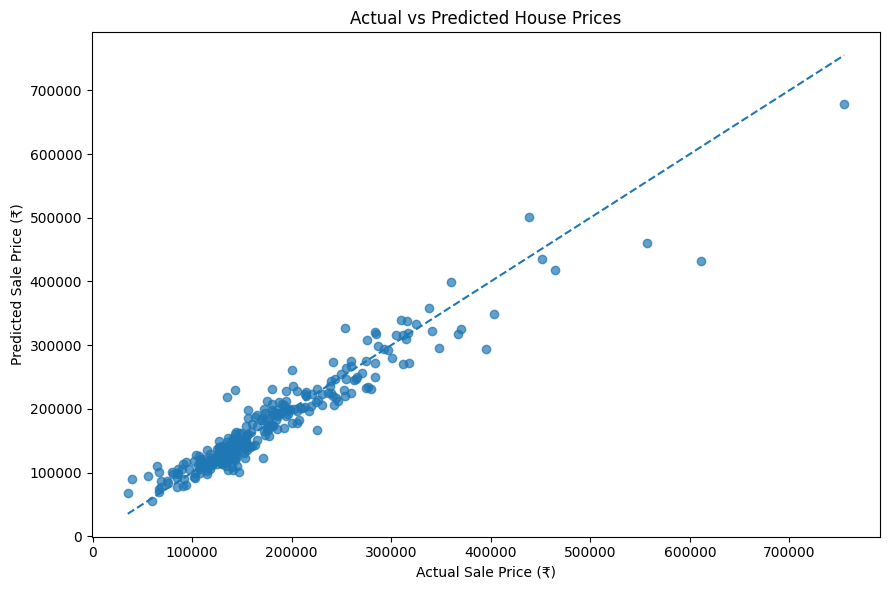

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    error_df["ActualPrice"],
    error_df["PredictedPrice"],
    alpha=0.7
)

low = min(error_df["ActualPrice"].min(),
          error_df["PredictedPrice"].min())
high = max(error_df["ActualPrice"].max(),
           error_df["PredictedPrice"].max())

plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Actual Sale Price (₹)")
plt.ylabel("Predicted Sale Price (₹)")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()


In [35]:

# Get the validation rows corresponding to the largest prediction errors
worst_indices = largest_errors.head(5).index

# Inspect important features for those houses
features_to_check = [
    "OverallQual",
    "GrLivArea",
    "YearBuilt",
    "GarageCars",
    "TotalBsmtSF",
    "FullBath",
    "Neighborhood",
    "SalePrice"
]

print(
    train.loc[worst_indices, features_to_check]
    .join(
        error_df.loc[worst_indices, ["PredictedPrice", "Error", "AbsoluteError"]]
    )
    .round(2)
    .to_string()
)


      OverallQual  GrLivArea  YearBuilt  GarageCars  TotalBsmtSF  FullBath Neighborhood  SalePrice  PredictedPrice      Error  AbsoluteError
898             9       2364       2009           3         2330         2      NridgHt     611657       432856.22  178800.78      178800.78
774             8       1973       2006           3         1935         2      NridgHt     395000       294330.29  100669.71      100669.71
1046            9       2868       2005           3         1992         3      StoneBr     556581       460089.15   96491.85       96491.85
588             5       1473       1968           1         1437         1      ClearCr     143000       228923.06  -85923.06       85923.06
628             5       2080       1969           2         1040         1        NAmes     135000       219239.04  -84239.04       84239.04


In [36]:

# Group houses according to their actual sale price
price_bins = [0, 100000, 200000, 300000, 400000, float("inf")]
price_labels = [
    "Under 100k",
    "100k–200k",
    "200k–300k",
    "300k–400k",
    "Over 400k"
]

error_df["PriceGroup"] = pd.cut(
    error_df["ActualPrice"],
    bins=price_bins,
    labels=price_labels,
    right=False
)

group_analysis = error_df.groupby(
    "PriceGroup", observed=False
).apply(
    lambda group: pd.Series({
        "HouseCount": len(group),
        "MeanActual": group["ActualPrice"].mean(),
        "MeanPredicted": group["PredictedPrice"].mean(),
        "MeanSignedError": group["Error"].mean(),
        "MAE": group["AbsoluteError"].mean()
    }),
    include_groups=False
)

print(group_analysis.round(2).to_string())


            HouseCount  MeanActual  MeanPredicted  MeanSignedError       MAE
PriceGroup                                                                  
Under 100k        26.0    76091.35       90667.62        -14576.27  17667.61
100k–200k        184.0   145749.93      146502.87          -752.94  12306.75
200k–300k         58.0   243004.60      237082.89          5921.71  20340.69
300k–400k         17.0   332272.18      318094.72         14177.45  30462.21
Over 400k          7.0   525995.43      467675.63         58319.80  76252.89


#Gradient Boosting

- Gradient Boosting builds trees sequentially. Each new tree tries to correct patterns in the errors left by the previous trees. Unlike Random Forest, which builds many trees independently and averages them, Gradient Boosting learns from the mistakes of the current ensemble.

In [37]:

import numpy as np

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Build the complete pipeline
gb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=42
    ))
])

# Train on log-transformed sale prices
gb_model.fit(X_train, np.log1p(y_train))

# Predict and convert back to original prices
gb_predictions_log = gb_model.predict(X_val)
gb_predictions = np.expm1(gb_predictions_log)

# Evaluate on the original price scale
gb_mae = mean_absolute_error(y_val, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_val, gb_predictions))
gb_r2 = r2_score(y_val, gb_predictions)

print(f"Validation MAE:  ₹{gb_mae:,.2f}")
print(f"Validation RMSE: ₹{gb_rmse:,.2f}")
print(f"Validation R²:   {gb_r2:.4f}")


Validation MAE:  ₹18,112.12
Validation RMSE: ₹31,851.38
Validation R²:   0.8677


In [38]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Combine actual prices, predictions, and validation features
residual_df = X_val[
    ["GrLivArea", "OverallQual", "YearBuilt"]
].copy()

residual_df["ActualPrice"] = y_val
residual_df["PredictedPrice"] = val_predictions_back

# Residual = actual - predicted
residual_df["Residual"] = (
    residual_df["ActualPrice"] - residual_df["PredictedPrice"]
)

residual_df["AbsoluteError"] = residual_df["Residual"].abs()

print(residual_df.head())


      GrLivArea  OverallQual  YearBuilt  ActualPrice  PredictedPrice  \
892        1068            6       1963       154500   151152.198948   
1105       2622            8       1994       325000   333142.530940   
413        1028            5       1927       115000   101802.920332   
522        1664            6       1947       159000   163873.455642   
1036       1620            9       2007       315500   338204.220152   

          Residual  AbsoluteError  
892    3347.801052    3347.801052  
1105  -8142.530940    8142.530940  
413   13197.079668   13197.079668  
522   -4873.455642    4873.455642  
1036 -22704.220152   22704.220152  


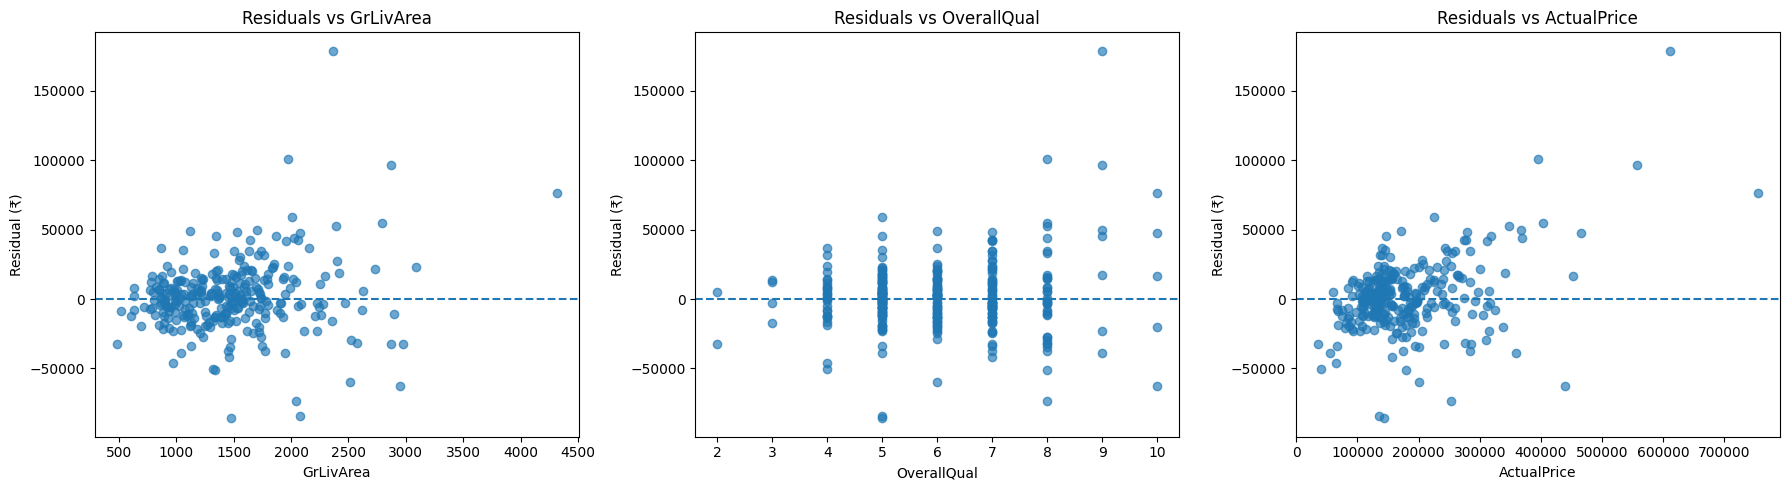

In [39]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ["GrLivArea", "OverallQual", "ActualPrice"]

for ax, feature in zip(axes, features):
    ax.scatter(
        residual_df[feature],
        residual_df["Residual"],
        alpha=0.65
    )
    ax.axhline(0, linestyle="--")
    ax.set_xlabel(feature)
    ax.set_ylabel("Residual (₹)")
    ax.set_title(f"Residuals vs {feature}")

plt.tight_layout()
plt.show()


In [40]:

quality_analysis = residual_df.groupby("OverallQual").agg(
    HouseCount=("Residual", "size"),
    MeanResidual=("Residual", "mean"),
    MAE=("AbsoluteError", "mean")
)

print(quality_analysis.round(2).to_string())


             HouseCount  MeanResidual       MAE
OverallQual                                    
2                     2     -13919.46  18691.59
3                     4       1606.34  11364.94
4                    28       -368.11  14243.64
5                    89         11.64  13133.38
6                    63        -37.23  13284.45
7                    61       1808.95  16207.87
8                    33        414.39  24420.77
9                     7      46611.79  64147.42
10                    5      11583.64  44826.72


In [41]:
quality_analysis = residual_df.groupby("OverallQual").agg(
    HouseCount=("Residual", "size"),
    MeanActualPrice=("ActualPrice", "mean"),
    MeanPredictedPrice=("PredictedPrice", "mean"),
    MeanResidual=("Residual", "mean"),
    MAE=("AbsoluteError", "mean")
)

print(quality_analysis.round(2).to_string())

             HouseCount  MeanActualPrice  MeanPredictedPrice  MeanResidual       MAE
OverallQual                                                                         
2                     2         47655.50            61574.96     -13919.46  18691.59
3                     4         83125.00            81518.66       1606.34  11364.94
4                    28        104394.50           104762.61       -368.11  14243.64
5                    89        131218.21           131206.57         11.64  13133.38
6                    63        156389.51           156426.74        -37.23  13284.45
7                    61        214308.52           212499.57       1808.95  16207.87
8                    33        273488.88           273074.49        414.39  24420.77
9                     7        399032.14           352420.36      46611.79  64147.42
10                    5        489646.00           478062.36      11583.64  44826.72


In [42]:
worst_predictions = residual_df.sort_values(
    by="AbsoluteError",
    ascending=False
).head(10)

print(
    worst_predictions[
        [
            "OverallQual",
            "GrLivArea",
            "YearBuilt",
            "ActualPrice",
            "PredictedPrice",
            "Residual",
            "AbsoluteError"
        ]
    ].round(2).to_string()
)

      OverallQual  GrLivArea  YearBuilt  ActualPrice  PredictedPrice   Residual  AbsoluteError
898             9       2364       2009       611657       432856.22  178800.78      178800.78
774             8       1973       2006       395000       294330.29  100669.71      100669.71
1046            9       2868       2005       556581       460089.15   96491.85       96491.85
588             5       1473       1968       143000       228923.06  -85923.06       85923.06
628             5       2080       1969       135000       219239.04  -84239.04       84239.04
691            10       4316       1994       755000       678314.25   76685.75       76685.75
581             8       2042       2008       253293       326646.37  -73353.37       73353.37
58             10       2945       2006       438780       501545.81  -62765.81       62765.81
529             6       2515       1957       200624       260282.96  -59658.96       59658.96
607             5       2008       1948       2250

In [43]:
worst_indices = worst_predictions.index

worst_house_details = train.loc[worst_indices].copy()

worst_house_details["PredictedPrice"] = (
    residual_df.loc[worst_indices, "PredictedPrice"]
)

worst_house_details["AbsoluteError"] = (
    residual_df.loc[worst_indices, "AbsoluteError"]
)

columns_to_inspect = [
    "OverallQual",
    "OverallCond",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageCars",
    "GarageArea",
    "YearBuilt",
    "YearRemodAdd",
    "Neighborhood",
    "ExterQual",
    "KitchenQual",
    "BsmtQual",
    "GarageType",
    "SalePrice",
    "PredictedPrice",
    "AbsoluteError"
]

print(
    worst_house_details[columns_to_inspect]
    .sort_values("AbsoluteError", ascending=False)
    .to_string()
)

      OverallQual  OverallCond  GrLivArea  TotalBsmtSF  GarageCars  GarageArea  YearBuilt  YearRemodAdd Neighborhood ExterQual KitchenQual BsmtQual GarageType  SalePrice  PredictedPrice  AbsoluteError
898             9            5       2364         2330           3         820       2009          2010      NridgHt        Ex          Ex       Ex     Attchd     611657   432856.215836  178800.784164
774             8            5       1973         1935           3         895       2006          2006      NridgHt        Gd          Gd       Gd     Attchd     395000   294330.285528  100669.714472
1046            9            5       2868         1992           3         716       2005          2006      StoneBr        Gd          Ex       Ex    BuiltIn     556581   460089.152223   96491.847777
588             5            8       1473         1437           1         452       1968          2003      ClearCr        TA          Ex       TA     Attchd     143000   228923.064684   85923.06

In [44]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

interaction_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("model", LinearRegression())
])

interaction_model.fit(X_train, np.log1p(y_train))

interaction_predictions = np.expm1(
    interaction_model.predict(X_val)
)

print("Interaction Model MAE:",
      mean_absolute_error(y_val, interaction_predictions))

print("Interaction Model RMSE:",
      np.sqrt(mean_squared_error(y_val, interaction_predictions)))

print("Interaction Model R²:",
      r2_score(y_val, interaction_predictions))

Interaction Model MAE: 17961.225614554838
Interaction Model RMSE: 29253.009951252032
Interaction Model R²: 0.8884351762763075


In [45]:
# Training predictions
train_predictions_log = log_model.predict(X_train)

train_predictions = np.expm1(train_predictions_log)

# Validation predictions
val_predictions = val_predictions_back

# Training metrics
train_mae = mean_absolute_error(y_train, train_predictions)
train_rmse = np.sqrt(
    mean_squared_error(y_train, train_predictions)
)
train_r2 = r2_score(y_train, train_predictions)

# Validation metrics
val_mae = mean_absolute_error(y_val, val_predictions)
val_rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)
val_r2 = r2_score(y_val, val_predictions)

print("TRAINING PERFORMANCE")
print("MAE:", train_mae)
print("RMSE:", train_rmse)
print("R2:", train_r2)

print("\nVALIDATION PERFORMANCE")
print("MAE:", val_mae)
print("RMSE:", val_rmse)
print("R2:", val_r2)

TRAINING PERFORMANCE
MAE: 13792.828944465966
RMSE: 22873.050710543004
R2: 0.9122856853415995

VALIDATION PERFORMANCE
MAE: 16969.819707723887
RMSE: 25451.6673763737
R2: 0.9155463073225509


In [46]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
import numpy as np

cv_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    cv_model,
    X_train,
    np.log1p(y_train),
    cv=kf,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    return_train_score=True
)

print("CV Training MAE:",
      -cv_results["train_mae"].mean())

print("CV Validation MAE:",
      -cv_results["test_mae"].mean())

print("CV Validation R2:",
      cv_results["test_r2"].mean())

CV Training MAE: 0.07270099695844909
CV Validation MAE: 0.09710124167517964
CV Validation R2: 0.846704263777766


In [47]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions on the log-price scale
oof_predictions_log = cross_val_predict(
    cv_model,
    X_train,
    np.log1p(y_train),
    cv=kf,
    method="predict"
)

# Convert predictions back to original price scale
oof_predictions = np.expm1(oof_predictions_log)

# Evaluate on original price scale
cv_mae = mean_absolute_error(y_train, oof_predictions)

cv_rmse = np.sqrt(
    mean_squared_error(y_train, oof_predictions)
)

cv_r2 = r2_score(y_train, oof_predictions)

print("CROSS-VALIDATION PERFORMANCE")
print("MAE:", cv_mae)
print("RMSE:", cv_rmse)
print("R2:", cv_r2)

CROSS-VALIDATION PERFORMANCE
MAE: 18173.839327851463
RMSE: 48490.02381718022
R2: 0.6057905022035917


In [48]:
# Create a DataFrame of out-of-fold predictions
cv_error_df = pd.DataFrame({
    "ActualPrice": y_train,
    "PredictedPrice": oof_predictions
})

cv_error_df["Residual"] = (
    cv_error_df["ActualPrice"] -
    cv_error_df["PredictedPrice"]
)

cv_error_df["AbsoluteError"] = (
    cv_error_df["Residual"].abs()
)

# Basic prediction statistics
print("Prediction range:")
print(cv_error_df["PredictedPrice"].describe())

print("\nLargest 10 prediction errors:")

print(
    cv_error_df.sort_values(
        "AbsoluteError",
        ascending=False
    ).head(10).round(2).to_string()
)

Prediction range:
count    1.168000e+03
mean     1.815491e+05
std      8.307392e+04
min      5.593865e+04
25%      1.296014e+05
50%      1.642341e+05
75%      2.137059e+05
max      1.424884e+06
Name: PredictedPrice, dtype: float64

Largest 10 prediction errors:
      ActualPrice  PredictedPrice    Residual  AbsoluteError
1298       160000      1424884.41 -1264884.41     1264884.41
523        184750       807174.48  -622424.48      622424.48
1182       745000       557486.62   187513.38      187513.38
440        555000       401007.88   153992.12      153992.12
1324       147000       287473.92  -140473.92      140473.92
185        475000       334602.00   140398.00      140398.00
688        392000       260937.82   131062.18      131062.18
583        325000       198433.02   126566.98      126566.98
53         385000       262865.07   122134.93      122134.93
1181       392500       270627.04   121872.96      121872.96


In [49]:
# Identify the two most problematic houses
problem_indices = [1298, 523]

# Inspect their original features
problem_houses = train.loc[problem_indices].copy()

print(problem_houses.T.to_string())

                    1298       523 
Id                  1299        524
MSSubClass            60         60
MSZoning              RL         RL
LotFrontage        313.0      130.0
LotArea            63887      40094
Street              Pave       Pave
Alley                NaN        NaN
LotShape             IR3        IR1
LandContour          Bnk        Bnk
Utilities         AllPub     AllPub
LotConfig         Corner     Inside
LandSlope            Gtl        Gtl
Neighborhood     Edwards    Edwards
Condition1         Feedr       PosN
Condition2          Norm       PosN
BldgType            1Fam       1Fam
HouseStyle        2Story     2Story
OverallQual           10         10
OverallCond            5          5
YearBuilt           2008       2007
YearRemodAdd        2008       2008
RoofStyle            Hip        Hip
RoofMatl         ClyTile    CompShg
Exterior1st       Stucco    CemntBd
Exterior2nd       Stucco    CmentBd
MasVnrType         Stone      Stone
MasVnrArea         796.0    

In [50]:
print("Actual log prices:")
print(np.log1p(y_train.loc[problem_indices]))

print("\nPredicted log prices:")
print(np.log1p(
    cv_error_df.loc[problem_indices, "PredictedPrice"]
))

Actual log prices:
1298    11.982935
523     12.126764
Name: SalePrice, dtype: float64

Predicted log prices:
1298    14.169602
523     13.601296
Name: PredictedPrice, dtype: float64


In [51]:
# Inspect distributions of important features
features_to_check = [
    "GrLivArea",
    "TotalBsmtSF",
    "BsmtFinSF1",
    "LotArea",
    "OverallQual",
    "PoolArea",
    "SalePrice"
]

print(
    train[features_to_check]
    .describe()
    .round(2)
    .to_string()
)

       GrLivArea  TotalBsmtSF  BsmtFinSF1    LotArea  OverallQual  PoolArea  SalePrice
count    1460.00      1460.00     1460.00    1460.00      1460.00   1460.00     1460.0
mean     1515.46      1057.43      443.64   10516.83         6.10      2.76   180921.2
std       525.48       438.71      456.10    9981.26         1.38     40.18    79442.5
min       334.00         0.00        0.00    1300.00         1.00      0.00    34900.0
25%      1129.50       795.75        0.00    7553.50         5.00      0.00   129975.0
50%      1464.00       991.50      383.50    9478.50         6.00      0.00   163000.0
75%      1776.75      1298.25      712.25   11601.50         7.00      0.00   214000.0
max      5642.00      6110.00     5644.00  215245.00        10.00    738.00   755000.0


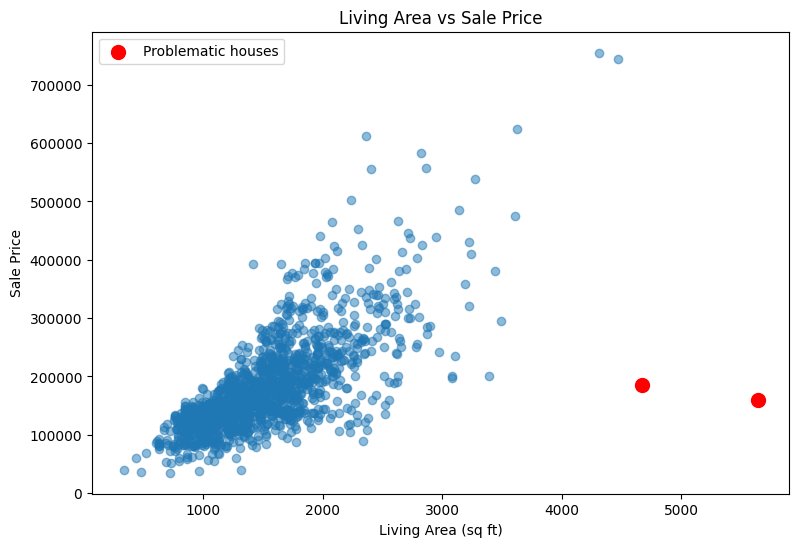

In [52]:
# Examine the relationship between living area and sale price
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    train["GrLivArea"],
    train["SalePrice"],
    alpha=0.5
)

plt.scatter(
    train.loc[[1298, 523], "GrLivArea"],
    train.loc[[1298, 523], "SalePrice"],
    color="red",
    s=100,
    label="Problematic houses"
)

plt.xlabel("Living Area (sq ft)")
plt.ylabel("Sale Price")
plt.title("Living Area vs Sale Price")
plt.legend()
plt.show()

In [53]:
# Identify the two unusual observations
outlier_indices = [1298, 523]

# Remove them only from training data
X_train_clean = X_train.drop(index=outlier_indices)
y_train_clean = y_train.drop(index=outlier_indices)

print("Original training rows:", len(X_train))
print("Cleaned training rows:", len(X_train_clean))
print("Validation rows:", len(X_val))

Original training rows: 1168
Cleaned training rows: 1166
Validation rows: 292


In [54]:
clean_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

# Train using log-transformed target
clean_model.fit(X_train_clean, np.log1p(y_train_clean))

# Predict on the original validation set
clean_predictions_log = clean_model.predict(X_val)

# Convert predictions back to original prices
clean_predictions = np.expm1(clean_predictions_log)

# Evaluate
clean_mae = mean_absolute_error(y_val, clean_predictions)
clean_rmse = np.sqrt(mean_squared_error(y_val, clean_predictions))
clean_r2 = r2_score(y_val, clean_predictions)

print("Clean Model MAE:", clean_mae)
print("Clean Model RMSE:", clean_rmse)
print("Clean Model R2:", clean_r2)

Clean Model MAE: 15214.185528453312
Clean Model RMSE: 23150.514981503708
Clean Model R2: 0.9301273075704859


In [55]:
clean_error_df = pd.DataFrame({
    "ActualPrice": y_val,
    "PredictedPrice": clean_predictions
})

clean_error_df["Error"] = (
    clean_error_df["ActualPrice"] -
    clean_error_df["PredictedPrice"]
)

clean_error_df["AbsoluteError"] = (
    clean_error_df["Error"].abs()
)

clean_error_df["ErrorPercent"] = (
    clean_error_df["Error"] /
    clean_error_df["ActualPrice"] * 100
)

# Display the 10 largest prediction errors
clean_error_df.sort_values(
    by="AbsoluteError",
    ascending=False
).head(10).round(2)

,ActualPrice,PredictedPrice,Error,AbsoluteError,ErrorPercent
774,395000,287297.21,107702.79,107702.79,27.27
691,755000,862611.51,-107611.51,107611.51,-14.25
588,143000,241414.50,-98414.50,98414.50,-68.82
898,611657,517442.04,94214.96,94214.96,15.40
581,253293,341635.42,-88342.42,88342.42,-34.88
58,438780,522397.64,-83617.64,83617.64,-19.06
1046,556581,481977.51,74603.49,74603.49,13.40
218,311500,245048.67,66451.33,66451.33,21.33
261,276000,337927.07,-61927.07,61927.07,-22.44
628,135000,193499.58,-58499.58,58499.58,-43.33


In [56]:
problem_indices = [774, 691]

features_to_inspect = [
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "Neighborhood",
    "SalePrice"
]

train.loc[
    problem_indices,
    features_to_inspect
]

,OverallQual,GrLivArea,TotalBsmtSF,GarageCars,YearBuilt,Neighborhood,SalePrice
774,8,1973,1935,3,2006,NridgHt,395000
691,10,4316,2444,3,1994,NoRidge,755000


In [58]:
extra_features = [
    "OverallQual",
    "OverallCond",
    "GrLivArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "GarageArea",
    "GarageCars",
    "YearBuilt",
    "YearRemodAdd",
    "KitchenQual",
    "ExterQual",
    "BsmtQual",
    "Neighborhood",
    "SaleCondition"
]

train.loc[[774, 691], extra_features]

,OverallQual,OverallCond,GrLivArea,TotalBsmtSF,1stFlrSF,2ndFlrSF,GarageArea,GarageCars,YearBuilt,YearRemodAdd,KitchenQual,ExterQual,BsmtQual,Neighborhood,SaleCondition
774,8,5,1973,1935,1973,0,895,3,2006,2006,Gd,Gd,Gd,NridgHt,Partial
691,10,6,4316,2444,2444,1872,832,3,1994,1995,Ex,Ex,Ex,NoRidge,Normal


In [59]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

In [60]:
log_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

In [61]:
log_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

In [62]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Original training data
original_results = cross_validate(
    log_model,
    X_train,
    y_train,
    cv=kf,
    scoring=scoring,
    return_train_score=True
)

# Cleaned training data
X_train_clean = X_train.drop(
    index=[1298, 523],
    errors="ignore"
)

y_train_clean = y_train.drop(
    index=[1298, 523],
    errors="ignore"
)

clean_results = cross_validate(
    log_model,
    X_train_clean,
    y_train_clean,
    cv=kf,
    scoring=scoring,
    return_train_score=True
)

In [63]:
def show_results(results, name):

    print(f"\n{name}")
    print("-" * 40)

    for metric in ["MAE", "RMSE"]:
        values = -results[f"test_{metric}"]

        print(
            f"Validation {metric}: "
            f"{values.mean():,.2f} "
            f"+/- {values.std():,.2f}"
        )

    print(
        f"Validation R2: "
        f"{results['test_R2'].mean():.4f}"
    )

    print(
        f"Training MAE: "
        f"{-results['train_MAE'].mean():,.2f}"
    )


show_results(original_results, "ORIGINAL DATA")
show_results(clean_results, "CLEANED DATA")


ORIGINAL DATA
----------------------------------------
Validation MAE: 18,172.86 +/- 1,134.76
Validation RMSE: 42,723.27 +/- 22,872.31
Validation R2: 0.6303
Training MAE: 13,079.10

CLEANED DATA
----------------------------------------
Validation MAE: 14,201.71 +/- 540.62
Validation RMSE: 20,960.95 +/- 1,128.87
Validation R2: 0.9260
Training MAE: 11,099.10


In [64]:
outlier_indices = [1298, 523]

print("Are these indices present in X_train?")

for idx in outlier_indices:
    print(idx, idx in X_train.index)

print("\nOriginal observations:")

display(
    pd.concat(
        [
            X_train.loc[
                X_train.index.intersection(outlier_indices)
            ],
            y_train.loc[
                y_train.index.intersection(outlier_indices)
            ].rename("SalePrice")
        ],
        axis=1
    )
)

Are these indices present in X_train?
1298 True
523 True

Original observations:


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
523,60,RL,130.0,40094,Pave,NaN,IR1,Bnk,AllPub,Inside,...,0,NaN,NaN,NaN,0,10,2007,New,Partial,184750
1298,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,Corner,...,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


In [65]:
import joblib
import numpy as np

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor

final_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LinearRegression())
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

final_model.fit(X_train_clean, y_train_clean)

print("Final model trained successfully!")

Final model trained successfully!


In [66]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

train_predictions = final_model.predict(X_train_clean)
val_predictions = final_model.predict(X_val)

print("FINAL MODEL PERFORMANCE")

print("Training MAE:",
      mean_absolute_error(y_train_clean, train_predictions))

print("Validation MAE:",
      mean_absolute_error(y_val, val_predictions))

print("Validation RMSE:",
      np.sqrt(mean_squared_error(y_val, val_predictions)))

print("Validation R2:",
      r2_score(y_val, val_predictions))

FINAL MODEL PERFORMANCE
Training MAE: 11313.069894798839
Validation MAE: 15214.185528453312
Validation RMSE: 23150.514981503708
Validation R2: 0.9301273075704859


In [67]:
import joblib

joblib.dump(final_model, "ames_housing_final_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [69]:
import pandas as pd

kaggle_test = pd.read_csv("/content/drive/MyDrive/house_prices ML/test.csv")

print("Test dataset shape:", kaggle_test.shape)
kaggle_test.head()

Test dataset shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [70]:
test_predictions = final_model.predict(kaggle_test)

print("Predictions generated:", len(test_predictions))
print("Minimum predicted price:", test_predictions.min())
print("Maximum predicted price:", test_predictions.max())

Predictions generated: 1459
Minimum predicted price: 53431.98104440095
Maximum predicted price: 1800207.5074623155


In [71]:
submission = pd.DataFrame({
    "Id": kaggle_test["Id"],
    "SalePrice": test_predictions
})

submission.to_csv("submission.csv", index=False)

print("Kaggle submission file created!")
submission.head()

Kaggle submission file created!


,Id,SalePrice
0,1461,117160.526414
1,1462,157165.825577
2,1463,179003.586733
3,1464,193238.693617
4,1465,198810.877664
